# TPI IA 2026 – Grupo 5
## 1. Análisis exploratorio (EDA)

### 1.0 Inspección del formato de los datos
Antes de programar el EDA verificamos cómo vienen las anotaciones, el envío, las preguntas y el vocabulario, para no asumir formatos.

In [1]:
import json
import pandas as pd
from pathlib import Path
from collections import Counter

# Ubicar la raíz sin adivinar la ruta de montaje
ROOT = next(Path("/kaggle/input").rglob("scene_schema.json")).parent
DEV, TEST, QA = ROOT/"development", ROOT/"tpi_ia_2026_competition_public", ROOT/"tpi_2026_qa_public"

# 1) Anotaciones: formato de máscaras y cajas
ann = json.load(open(DEV/"annotations.json"))
a0 = ann["annotations"][0]
print("Imágenes / anotaciones / categorías:", len(ann["images"]), len(ann["annotations"]), len(ann["categories"]))
print("Claves de imagen:", list(ann["images"][0].keys()))
print("Claves de anotación:", list(a0.keys()))
print("bbox:", a0["bbox"], "| area:", a0["area"])
print("Tipos de máscara:", Counter(type(a["segmentation"]).__name__ for a in ann["annotations"]))

# 2) Envío: cómo es una fila de desarrollo completa
sub = pd.read_csv(ROOT/"sample_submission.csv")
dev = sub[~sub.image_id.str.startswith("test_")]
print("\nIDs de desarrollo:", dev.image_id.head(3).tolist())
print(json.dumps(json.loads(dev.iloc[0].SceneJSON), ensure_ascii=False)[:2000])

# 3) Preguntas: cantidad por tipo y un ejemplo de cada una
qs = pd.read_json(QA/"questions_dev.jsonl", lines=True)
print("\n", qs.type.value_counts())
print(qs.groupby("type").first()[["question", "answer_format", "class_en"]].to_string())

# 4) Vocabulario del test vs. categorías anotadas
cats = pd.read_csv(TEST/"categories.csv")
print("\ncategories.csv:", cats.shape, list(cats.columns)); print(cats.head(3))

Imágenes / anotaciones / categorías: 120 1790 120
Claves de imagen: ['id', 'file_name', 'width', 'height', 'license', 'neg_category_ids', 'not_exhaustive_category_ids']
Claves de anotación: ['id', 'image_id', 'category_id', 'bbox', 'segmentation', 'area', 'iscrowd']
bbox: [148.14, 69.52, 198.41, 160.86] | area: 31077.0
Tipos de máscara: Counter({'list': 1790})

IDs de desarrollo: ['tpi_0001', 'tpi_0002', 'tpi_0003']
{"image": {"id": "tpi_0001", "width": 480, "height": 640}, "objects": [{"id": "example_1", "category_id": 1, "confidence": 0.5, "bbox": [0, 0, 1, 1], "mask": {"size": [640, 480], "counts": [0, 1, 307199]}, "centroid": [0, 0], "area_ratio": 3.2552083333333335e-06, "position": "top_left", "size": "small"}], "relations": [], "questions": [], "questions_llm": []}

 type
description    20
count          10
existence      10
relation       10
position        5
size            5
Name: count, dtype: int64
                                                                             

### 1.1 Carga de datos
Armamos dos tablas: una fila por imagen y una fila por objeto anotado. Las anotaciones se usan sólo para EDA y evaluación, nunca dentro de la pipeline de predicción.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle, Polygon

id2name = dict(zip(cats.category_id, cats.category_name))

# Estilo común: un solo color de datos, gris para referencias, grilla suave
AZUL, GRIS = "#3b6ea8", "#8a9099"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold"})

# Una fila por imagen
imgs = pd.DataFrame(ann["images"])
imgs["fname"] = imgs.file_name.map(lambda s: Path(s).name)

# Una fila por objeto (sin el polígono, que es pesado)
objs = pd.DataFrame(ann["annotations"]).drop(columns="segmentation")
objs[["x", "y", "w", "h"]] = pd.DataFrame(objs.bbox.tolist(), index=objs.index)
objs = objs.merge(imgs[["id", "width", "height"]].rename(columns={"id": "image_id"}), on="image_id")
objs["category_name"] = objs.category_id.map(id2name)
objs["area_ratio"] = objs.area / (objs.width * objs.height)
objs["cx"], objs["cy"] = objs.x + objs.w / 2, objs.y + objs.h / 2   # centro de la caja (aprox. del centroide)

# Chequeo de consistencia del vocabulario
ann_cats = {c["id"]: c["name"] for c in ann["categories"]}
print("Objetos:", len(objs))
print("¿Mismos IDs en categories.csv y annotations.json?", set(id2name) == set(ann_cats))
print("¿Mismos nombres?", all(id2name[k] == ann_cats[k] for k in id2name))
print("Ejemplo de file_name:", imgs.file_name.iloc[0])

Objetos: 1790
¿Mismos IDs en categories.csv y annotations.json? True
¿Mismos nombres? True
Ejemplo de file_name: tpi_0001.jpg


### 1.2 ¿Cuántos objetos hay por imagen?
Motiva: el número máximo de detecciones por imagen y qué tan bajo puede ser el umbral de confianza.

       objetos  clases distintas
count    120.0             120.0
mean      14.9               6.4
std       11.6               1.4
min        5.0               3.0
25%        8.0               6.0
50%       10.5               7.0
75%       15.2               7.2
max       66.0               8.0
Imagen más cargada: 66 objetos | límite del schema: 300


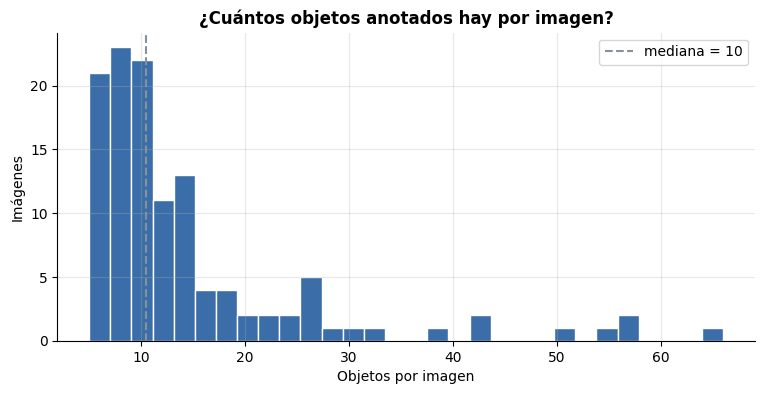

In [3]:
n_obj = objs.groupby("image_id").size().reindex(imgs.id, fill_value=0)
n_cls = objs.groupby("image_id").category_id.nunique().reindex(imgs.id, fill_value=0)
print(pd.DataFrame({"objetos": n_obj.describe(), "clases distintas": n_cls.describe()}).round(1))
print("Imagen más cargada:", n_obj.max(), "objetos | límite del schema: 300")

ax = n_obj.plot.hist(bins=30, color=AZUL, edgecolor="white")
ax.axvline(n_obj.median(), color=GRIS, ls="--", label=f"mediana = {n_obj.median():.0f}")
ax.set(title="¿Cuántos objetos anotados hay por imagen?", xlabel="Objetos por imagen", ylabel="Imágenes")
ax.legend(); plt.show()

### 1.3 ¿Qué tan chicos son los objetos?
Motiva: la elección del detector (YOLO-World rinde peor con objetos chicos) y la resolución de entrada.
Umbrales de referencia COCO: chico < 32² px, grande ≥ 96² px.

Chicos (<32² px): 54% | Medianos: 33% | Grandes (≥96² px): 13%
Percentiles de area_ratio: {0.1: 0.0002, 0.25: 0.0008, 0.5: 0.0029, 0.75: 0.0127, 0.9: 0.0468}


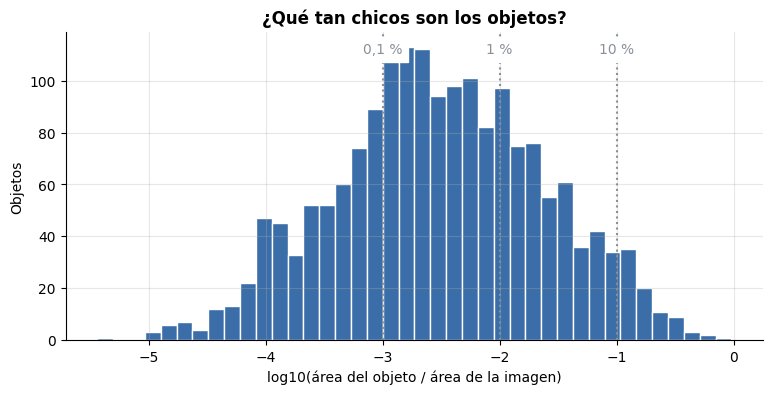

In [4]:
chico = (objs.area < 32**2).mean()
grande = (objs.area >= 96**2).mean()
print(f"Chicos (<32² px): {chico:.0%} | Medianos: {1 - chico - grande:.0%} | Grandes (≥96² px): {grande:.0%}")
print("Percentiles de area_ratio:", objs.area_ratio.quantile([.1, .25, .5, .75, .9]).round(4).to_dict())

ax = np.log10(objs.area_ratio).plot.hist(bins=40, color=AZUL, edgecolor="white")
for v, t in [(-3, "0,1 %"), (-2, "1 %"), (-1, "10 %")]:
    ax.axvline(v, color=GRIS, ls=":")
    ax.text(v, ax.get_ylim()[1] * 0.93, t, ha="center", color=GRIS, backgroundcolor="white")
ax.set(title="¿Qué tan chicos son los objetos?", xlabel="log10(área del objeto / área de la imagen)", ylabel="Objetos")
plt.show()

### 1.4 ¿Qué clases aparecen mucho y cuáles poco?
Motiva: cómo armar el vocabulario y qué clases van a pesar más en el F1.

Clases con al menos una anotación: 120 de 120
Clases con ≤ 3 instancias: 2
Clases presentes en una sola imagen: 0
Las 10 clases más frecuentes concentran el 20% de los objetos


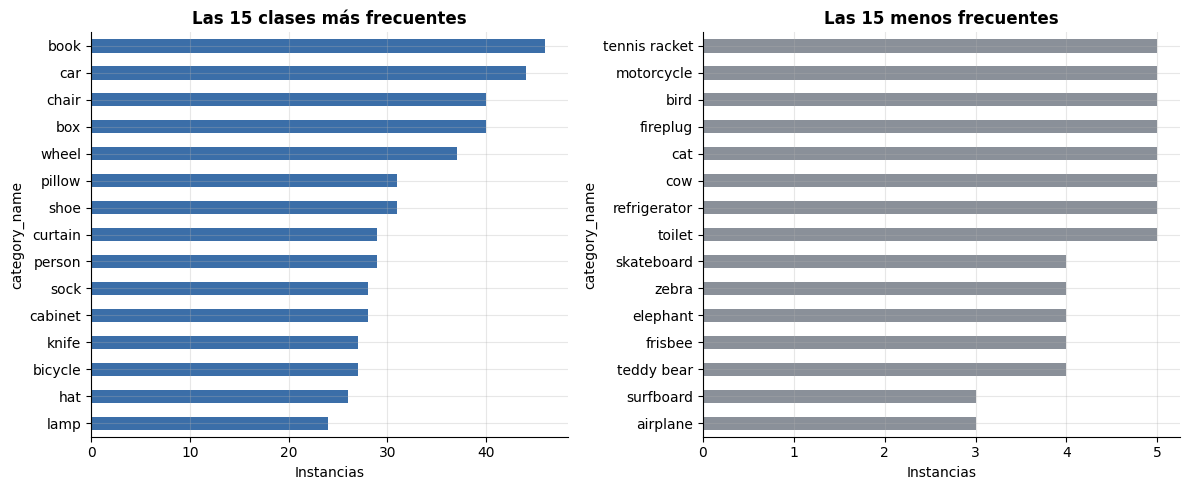

In [5]:
freq = objs.category_name.value_counts()
imgs_por_clase = objs.groupby("category_name").image_id.nunique()
print(f"Clases con al menos una anotación: {freq.size} de {len(cats)}")
print(f"Clases con ≤ 3 instancias: {(freq <= 3).sum()}")
print(f"Clases presentes en una sola imagen: {(imgs_por_clase == 1).sum()}")
print(f"Las 10 clases más frecuentes concentran el {freq.head(10).sum() / freq.sum():.0%} de los objetos")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
freq.head(15)[::-1].plot.barh(ax=axes[0], color=AZUL)
axes[0].set(title="Las 15 clases más frecuentes", xlabel="Instancias")
freq.tail(15)[::-1].plot.barh(ax=axes[1], color=GRIS)
axes[1].set(title="Las 15 menos frecuentes", xlabel="Instancias")
plt.tight_layout(); plt.show()

### 1.5 ¿Qué parte de las predicciones se puede evaluar? (LVIS)
Un par imagen-clase sólo se evalúa si es positivo (tiene anotaciones) o negativo verificado (`neg_category_ids`).
Motiva: la métrica local tiene que ignorar los pares no evaluables, y hay que reportar la cobertura.

In [6]:
pos = objs.groupby("image_id").category_id.apply(set).to_dict()
n_pos = sum(len(s) for s in pos.values())
n_neg = imgs.neg_category_ids.str.len().sum()
total = len(imgs) * len(cats)

print(f"Pares imagen-clase posibles: {total}")
print(f"  Positivos:             {n_pos:5d} ({n_pos / total:.1%})")
print(f"  Negativos verificados: {n_neg:5d} ({n_neg / total:.1%})")
print(f"  No evaluables:         {total - n_pos - n_neg:5d} ({1 - (n_pos + n_neg) / total:.1%})")

no_exh = sum(len(set(r.not_exhaustive_category_ids) & pos.get(r.id, set())) for r in imgs.itertuples())
print(f"Positivos marcados como no exhaustivos: {no_exh} ({no_exh / n_pos:.0%} de los positivos)")
solap = sum(len(set(r.neg_category_ids) & pos.get(r.id, set())) for r in imgs.itertuples())
print(f"Chequeo: clases a la vez positivas y negativas en una imagen: {solap} (debería ser 0)")

Pares imagen-clase posibles: 14400
  Positivos:               764 (5.3%)
  Negativos verificados:   118 (0.8%)
  No evaluables:         13518 (93.9%)
Positivos marcados como no exhaustivos: 47 (6% de los positivos)
Chequeo: clases a la vez positivas y negativas en una imagen: 0 (debería ser 0)


### 1.6 ¿Cuánto se solapan objetos de la misma clase?
Motiva: el umbral de NMS. Si objetos reales de la misma clase se solapan mucho, un NMS agresivo los borraría.

Pares de la misma clase dentro de una imagen: 3836
  con IoU > 0.3: 41 (1.1%)
  con IoU > 0.5: 19 (0.5%)
  con IoU > 0.7: 5 (0.1%)


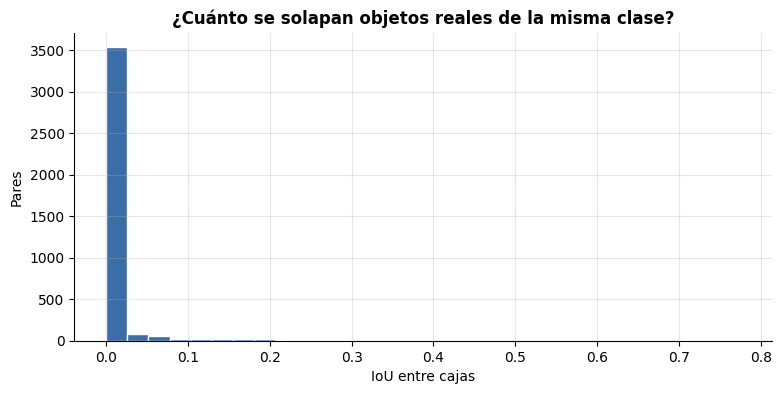

In [7]:
def iou_xywh(a, b):
    """IoU entre dos cajas en formato [x, y, ancho, alto]."""
    iw = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    ih = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = iw * ih
    return inter / (a[2] * a[3] + b[2] * b[3] - inter + 1e-9)

ious = []
for _, g in objs.groupby(["image_id", "category_id"]):
    b = g.bbox.tolist()
    ious += [iou_xywh(b[i], b[j]) for i in range(len(b)) for j in range(i + 1, len(b))]
ious = np.array(ious)

print(f"Pares de la misma clase dentro de una imagen: {len(ious)}")
for t in (0.3, 0.5, 0.7):
    print(f"  con IoU > {t}: {(ious > t).sum()} ({(ious > t).mean():.1%})")

ax = pd.Series(ious).plot.hist(bins=30, color=AZUL, edgecolor="white")
ax.set(title="¿Cuánto se solapan objetos reales de la misma clase?", xlabel="IoU entre cajas", ylabel="Pares")
plt.show()

### 1.7 ¿Dónde caen los objetos en la grilla 3×3?
Motiva: valida la regla de posición del SceneJSON y muestra si hay sesgo espacial.

Proporción por zona:
col_0     0     1     2
row_0                  
0      0.07  0.08  0.09
1      0.12  0.19  0.13
2      0.09  0.14  0.09


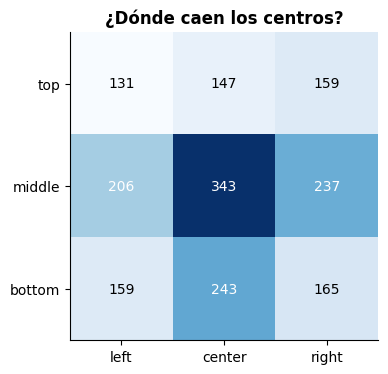

In [8]:
col = np.minimum((objs.cx / (objs.width / 3)).astype(int), 2)
fila = np.minimum((objs.cy / (objs.height / 3)).astype(int), 2)
grid = pd.crosstab(fila, col).reindex(index=range(3), columns=range(3), fill_value=0)
print("Proporción por zona:")
print((grid / grid.values.sum()).round(2))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(grid, cmap="Blues"); ax.grid(False)
for r in range(3):
    for c in range(3):
        v = grid.iloc[r, c]
        ax.text(c, r, v, ha="center", va="center", color="white" if v > grid.values.max() / 2 else "black")
ax.set(xticks=range(3), yticks=range(3), xticklabels=["left", "center", "right"],
       yticklabels=["top", "middle", "bottom"], title="¿Dónde caen los centros?")
plt.show()

### 1.8 ¿Qué piden las preguntas y cuántas son ambiguas?
Para cada pregunta contamos cuántas instancias reales hay de la clase preguntada.
Motiva: qué operaciones implementar primero y cómo tratar "la instancia" cuando hay varias.

In [9]:
f2id = dict(zip(imgs.fname, imgs.id))
cnt = objs.groupby(["image_id", "category_name"]).size()

faltan = {c for l in qs.class_en for c in l} - set(cats.category_name)
print("Clases preguntadas que no están en el vocabulario:", faltan or "ninguna")
print("Imágenes de las preguntas que no aparecen en annotations:", set(qs.image_file) - set(f2id) or "ninguna")
print("Imágenes distintas en el benchmark:", qs.image_file.nunique())

qs["n_gt"] = qs.apply(lambda r: cnt.get((f2id[r.image_file], r.class_en[0]), 0) if r.class_en else np.nan, axis=1)
print("\nInstancias reales de la clase preguntada, por tipo:")
print(qs.groupby("type").n_gt.agg(["count", "mean", "min", "max"]).round(1))

amb = qs[qs.type.isin(["position", "size", "relation"]) & (qs.n_gt > 1)]
print(f"\nPreguntas sobre 'la instancia' con más de una instancia real: {len(amb)}")
print(amb[["question_id", "type", "class_en", "n_gt"]].to_string(index=False))
print("\nRespuestas de existencia que serían 'no' (0 instancias):", (qs[qs.type == "existence"].n_gt == 0).sum())

Clases preguntadas que no están en el vocabulario: ninguna
Imágenes de las preguntas que no aparecen en annotations: ninguna
Imágenes distintas en el benchmark: 20

Instancias reales de la clase preguntada, por tipo:
             count  mean  min  max
type                              
count           10   2.3  2.0  4.0
description      0   NaN  NaN  NaN
existence       10   0.8  0.0  4.0
position         5   1.0  1.0  1.0
relation        10   1.0  1.0  1.0
size             5   1.0  1.0  1.0

Preguntas sobre 'la instancia' con más de una instancia real: 0
Empty DataFrame
Columns: [question_id, type, class_en, n_gt]
Index: []

Respuestas de existencia que serían 'no' (0 instancias): 5


### 1.9 Verificación visual de las anotaciones
Dibujamos cajas (xywh) y polígonos para confirmar que el formato se interpreta bien. Mostramos la imagen con menos objetos, la mediana y la más cargada.

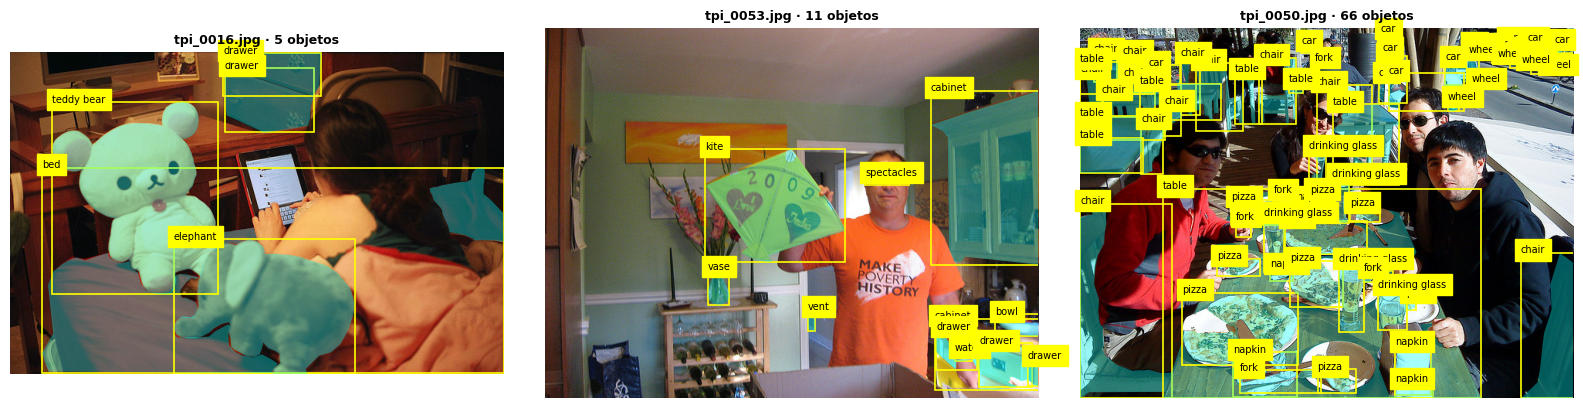

In [10]:
def mostrar(img_id, ax):
    info = imgs.set_index("id").loc[img_id]
    ax.imshow(Image.open(DEV / "images" / info.fname)); ax.axis("off")
    for a in (x for x in ann["annotations"] if x["image_id"] == img_id):
        x, y, w, h = a["bbox"]
        ax.add_patch(Rectangle((x, y), w, h, fill=False, ec="yellow", lw=1.2))
        for poly in a["segmentation"]:
            ax.add_patch(Polygon(np.array(poly).reshape(-1, 2), fc="cyan", alpha=0.35))
        ax.text(x, y, id2name[a["category_id"]], fontsize=7, backgroundcolor="yellow")
    ax.set_title(f"{info.fname} · {n_obj[img_id]} objetos", fontsize=9)

orden = n_obj.sort_values()
elegidas = [orden.index[0], orden.index[len(orden) // 2], orden.index[-1]]
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
for i, ax in zip(elegidas, axes):
    mostrar(i, ax)
plt.tight_layout(); plt.show()

### 1.10 Conclusiones del EDA: observación → decisión

| # | Observación | Decisión que motiva |
|---|---|---|
| 1.2 | 14,9 objetos por imagen en promedio (mediana 10,5; máx. 66) y entre 3 y 8 clases distintas por imagen. | El límite de 300 objetos del schema no es restricción. Dejamos un tope de detecciones holgado (~150) y no filtramos por cantidad. |
| 1.3 | El 54 % de los objetos es chico (< 32² px); la mediana ocupa el 0,29 % de la imagen. | Priorizamos detectores fuertes en objetos chicos (OWLv2 / Grounding DINO) sobre YOLO-World. La resolución de entrada es candidata a experimento controlado. |
| 1.4 | Las 120 clases tienen anotaciones; ninguna aparece en una sola imagen y las 10 más frecuentes suman sólo el 20 %. | Usamos el vocabulario completo de 120 clases: ninguna clase domina el F1, así que no conviene descartar clases raras. |
| 1.5 | El 93,9 % de los pares imagen-clase no es evaluable; sólo hay 118 negativos verificados (~1 por imagen) y el 6 % de los positivos es no exhaustivo. | Un falso positivo de una clase ausente casi nunca penaliza, pero los duplicados dentro de clases presentes sí. La métrica local implementa las reglas LVIS y reporta la cobertura. Esperamos un umbral óptimo bajo (a verificar con el barrido de F1). |
| 1.6 | Sólo el 0,5 % de los pares de objetos reales de la misma clase tiene IoU > 0,5. | NMS por clase con umbral 0,5 es seguro: casi no borra objetos reales. |
| 1.7 | Los centros se concentran en la fila del medio y la columna central (19 % en `center`), pero todas las zonas tienen al menos 7 %. | No hay sesgo fuerte: la regla de grilla 3×3 por centroide es adecuada. |
| 1.8 | Todas las clases preguntadas están en el vocabulario. En `position`, `size` y `relation` la clase tiene exactamente 1 instancia real; en `count` hay entre 2 y 4; 5 de 10 preguntas de `existence` tienen respuesta "no". | Si el detector predice varias instancias, se responde con la de mayor confianza. Para `existence` importa la precisión: un falso positivo cambia la respuesta. |
| 1.9 | Cajas y polígonos coinciden con los objetos de la foto. | Confirmado: `bbox` en formato `[x, y, ancho, alto]`. Para medir máscaras hay que rasterizar los polígonos (pycocotools). |

**Pendientes:** la definición oficial de `small / medium / large` y el orden del RLE (filas o columnas) se verifican en la Fase 3.

## 2. Detección de objetos

Objetivo de la fase: elegir y ajustar un detector open-vocabulary, medido con una métrica local que respeta las reglas de LVIS.

**Regla anti-fuga:** la función `detectar()` recibe sólo la imagen y el vocabulario (`categories.csv`). Las anotaciones se usan únicamente en `evaluar_cajas()`.

### 2.1 Métrica local (F1 de cajas con reglas LVIS)
Para cada imagen y clase:
- **Clase positiva** (tiene anotaciones): emparejamos predicciones con cajas reales de mayor a menor confianza, con IoU ≥ 0,5. Emparejada = TP; sin pareja = FP, salvo que la clase sea *no exhaustiva*, donde se ignora. Cajas reales sin pareja = FN.
- **Clase negativa verificada**: toda predicción es FP.
- **Resto**: la predicción se ignora (no es evaluable).

Supuesto: sumamos TP/FP/FN de todas las imágenes antes de calcular el F1 (micro). La métrica oficial de Kaggle puede agregar distinto.

In [11]:
from collections import defaultdict

img_meta = {r.id: r for r in imgs.itertuples()}
gt_by = defaultdict(list)
for a in ann["annotations"]:
    gt_by[(a["image_id"], a["category_id"])].append(a["bbox"])

def evaluar_cajas(preds, iou_thr=0.5, detalle=False):
    """preds: DataFrame con image_id, category_id, score y bbox [x, y, w, h]. Aplica las reglas LVIS."""
    grupos = {k: g.sort_values("score", ascending=False).bbox.tolist()
              for k, g in preds.groupby(["image_id", "category_id"])}
    cats_pred = defaultdict(set)
    for i, c in grupos:
        cats_pred[i].add(c)
    cnt = defaultdict(lambda: np.zeros(4, int))  # TP, FP, FN, ignoradas (por clase)
    for img_id, r in img_meta.items():
        neg, noexh = set(r.neg_category_ids), set(r.not_exhaustive_category_ids)
        for c in pos.get(img_id, set()) | cats_pred[img_id]:
            pb, gts = grupos.get((img_id, c), []), gt_by.get((img_id, c), [])
            if gts:
                usado = [False] * len(gts)
                for b in pb:
                    ious = [-1 if usado[k] else iou_xywh(b, g) for k, g in enumerate(gts)]
                    k = int(np.argmax(ious))
                    if ious[k] >= iou_thr:
                        usado[k] = True; cnt[c][0] += 1
                    elif c in noexh:
                        cnt[c][3] += 1
                    else:
                        cnt[c][1] += 1
                cnt[c][2] += usado.count(False)
            elif c in neg:
                cnt[c][1] += len(pb)
            else:
                cnt[c][3] += len(pb)
    tp, fp, fn, ign = np.sum(list(cnt.values()), axis=0)
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    res = dict(P=P, R=R, F1=2 * P * R / (P + R) if P + R else 0.0, TP=tp, FP=fp, FN=fn, ignoradas=ign,
               cobertura=(tp + fp) / (tp + fp + ign) if tp + fp + ign else 0.0)
    if detalle:
        tabla = pd.DataFrame(cnt, index=["TP", "FP", "FN", "ign"]).T
        tabla.index = tabla.index.map(id2name)
        return res, tabla
    return res

# Pruebas de cordura de la métrica
gt_df = objs[["image_id", "category_id", "bbox"]].assign(score=1.0)
print("GT como predicción (esperado F1 = 1):", {k: round(float(v), 3) for k, v in evaluar_cajas(gt_df).items()})
corridas = gt_df.assign(bbox=gt_df.bbox.map(lambda b: [b[0] + b[2], b[1], b[2], b[3]]))
print("GT corrida un ancho (esperado F1 ≈ 0):", round(evaluar_cajas(corridas)["F1"], 3))
mitad = gt_df.sample(frac=0.5, random_state=0)
print("Sólo la mitad del GT (esperado P = 1, R ≈ 0,5):", {k: round(float(evaluar_cajas(mitad)[k]), 3) for k in ("P", "R")})

GT como predicción (esperado F1 = 1): {'P': 1.0, 'R': 1.0, 'F1': 1.0, 'TP': 1790.0, 'FP': 0.0, 'FN': 0.0, 'ignoradas': 0.0, 'cobertura': 1.0}
GT corrida un ancho (esperado F1 ≈ 0): 0.038
Sólo la mitad del GT (esperado P = 1, R ≈ 0,5): {'P': 1.0, 'R': 0.5}


### 2.2 Línea base: OWLv2 con el vocabulario completo
Elegimos **OWLv2** (`google/owlv2-base-patch16-ensemble`) como línea base: es open-vocabulary, procesa las 120 clases en una sola pasada y rinde bien con objetos chicos (54 % del dataset, ver 1.3).
Guardamos todas las detecciones con confianza ≥ 0,05 y después elegimos el umbral midiendo, sin volver a usar la GPU.

In [12]:
import time
import torch
from transformers import Owlv2Processor, Owlv2ForObjectDetection

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device, torch.cuda.get_device_name(0) if device == "cuda" else "")

MODELO = "google/owlv2-base-patch16-ensemble"
processor = Owlv2Processor.from_pretrained(MODELO)
model = Owlv2ForObjectDetection.from_pretrained(MODELO).to(device).eval()

# El nombre del post-procesado cambió entre versiones de transformers
post_proceso = getattr(processor, "post_process_grounded_object_detection", None) or processor.image_processor.post_process_object_detection

VOCAB = cats.category_name.tolist()
CAT_IDS = cats.category_id.tolist()
PROMPTS = [f"a photo of a {n}" for n in VOCAB]

@torch.no_grad()
def detectar(img_path, umbral=0.05):
    """Recibe SÓLO una imagen y el vocabulario. No lee anotaciones."""
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    inp = processor(text=[PROMPTS], images=im, return_tensors="pt").to(device)
    out = model(**inp)
    S = max(W, H)  # OWLv2 rellena la imagen hasta hacerla cuadrada
    res = post_proceso(out, threshold=umbral, target_sizes=torch.tensor([[S, S]], device=device))[0]
    filas = []
    for (x1, y1, x2, y2), s, l in zip(res["boxes"].tolist(), res["scores"].tolist(), res["labels"].tolist()):
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
        if x2 > x1 and y2 > y1:
            filas.append(dict(category_id=CAT_IDS[l], score=s, bbox=[x1, y1, x2 - x1, y2 - y1]))
    return filas

# Prueba con una imagen
t0 = time.time()
prueba = pd.DataFrame(detectar(DEV / "images" / imgs.fname.iloc[0]))
print(f"{len(prueba)} detecciones en {time.time() - t0:.1f} s")
print(prueba.assign(clase=prueba.category_id.map(id2name)).sort_values("score", ascending=False).head(10))

Dispositivo: cuda Tesla T4


preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

90 detecciones en 4.0 s
    category_id     score                                               bbox  \
85           19  0.588489  [66.89179229736328, 476.571044921875, 60.00298...   
4            86  0.492368  [144.48605346679688, 38.46576690673828, 201.23...   
21           67  0.457331  [126.54450988769531, 193.5514678955078, 22.996...   
46           89  0.441017  [109.08683013916016, 315.70721435546875, 268.8...   
57           11  0.381622  [158.06129455566406, 392.08087158203125, 70.59...   
58           11  0.360651  [257.73370361328125, 390.8590393066406, 68.904...   
1           114  0.354903  [146.56988525390625, 35.246055603027344, 197.3...   
61           62  0.346548  [246.32644653320312, 376.51336669921875, 125.8...   
54           62  0.339436  [119.65005493164062, 379.2236633300781, 124.64...   
20          114  0.314387  [179.97161865234375, 167.80841064453125, 51.85...   

          clase  
85    trash can  
4        mirror  
21  wall socket  
46         sink  
57   

### 2.3 Detección sobre las 120 imágenes de desarrollo
Corremos OWLv2 una sola vez y guardamos las detecciones crudas en `/kaggle/working/`. Todas las decisiones que siguen (NMS, umbral) se ajustan sobre este archivo, sin gastar más GPU.

In [13]:
SALIDA = Path("/kaggle/working")
filas, tiempos = [], []
for img_id, fname in imgs[["id", "fname"]].itertuples(index=False):
    t0 = time.time()
    for d in detectar(DEV / "images" / fname, umbral=0.05):
        d["image_id"] = img_id
        filas.append(d)
    tiempos.append(time.time() - t0)

dets = pd.DataFrame(filas)
dets.to_pickle(SALIDA / "dets_owlv2_base_dev.pkl")
print(f"{len(dets)} detecciones crudas | {np.mean(tiempos):.2f} s por imagen | total {np.sum(tiempos) / 60:.1f} min")
print("Detecciones por imagen (umbral 0,05):", dets.groupby("image_id").size().describe().round(1).to_dict())

20396 detecciones crudas | 0.43 s por imagen | total 0.9 min
Detecciones por imagen (umbral 0,05): {'count': 120.0, 'mean': 170.0, 'std': 122.4, 'min': 38.0, '25%': 80.8, '50%': 130.5, '75%': 220.2, 'max': 724.0}


### 2.4 NMS por clase y elección del umbral de confianza
Aplicamos NMS por clase con IoU 0,5 (justificado en 1.6) y barremos el umbral de confianza. Elegimos el umbral que maximiza el F1 en desarrollo; también mostramos cuántas predicciones fueron evaluables (cobertura, ver 1.5).

NMS: 20396 -> 16561 detecciones
 umbral     P     R    F1   TP   FP   FN  ignoradas  cobertura
  0.050 0.300 0.766 0.432 1371 3193  419      11997      0.276
  0.075 0.399 0.748 0.521 1339 2014  451       7545      0.308
  0.100 0.490 0.722 0.584 1292 1346  498       5246      0.335
  0.125 0.557 0.696 0.619 1246  991  544       3786      0.371
  0.150 0.625 0.661 0.643 1184  709  606       2807      0.403
  0.200 0.732 0.578 0.646 1035  378  755       1638      0.463
  0.250 0.820 0.506 0.625  905  199  885        951      0.537
  0.300 0.865 0.432 0.576  773  121 1017        565      0.613
  0.400 0.921 0.275 0.423  492   42 1298        176      0.752
  0.500 0.958 0.140 0.244  250   11 1540         44      0.856

Mejor umbral: 0.2 -> F1 = 0.646 (P = 0.732, R = 0.578)
Sin NMS, mismo umbral: 0.633


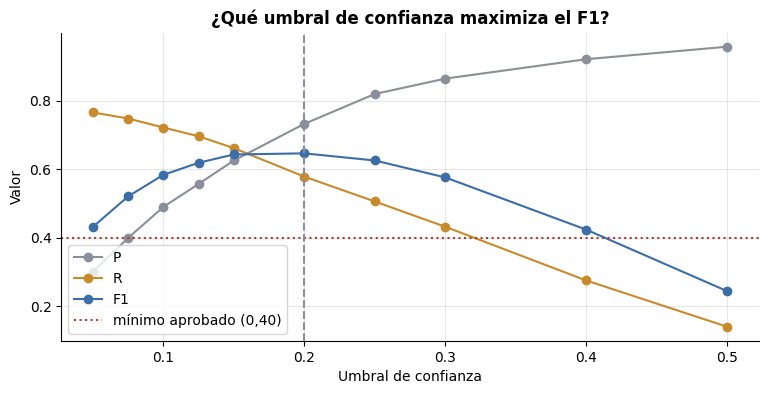

In [14]:
from torchvision.ops import batched_nms

def aplicar_nms(df, iou=0.5):
    """NMS por clase dentro de cada imagen. Las cajas vienen en [x, y, w, h]."""
    partes = []
    for _, g in df.groupby("image_id"):
        b = torch.tensor(g.bbox.tolist(), dtype=torch.float32)
        b[:, 2:] += b[:, :2]  # a [x1, y1, x2, y2]
        keep = batched_nms(b, torch.tensor(g.score.values, dtype=torch.float32), torch.tensor(g.category_id.values), iou)
        partes.append(g.iloc[keep.numpy()])
    return pd.concat(partes, ignore_index=True)

dets_nms = aplicar_nms(dets)
print(f"NMS: {len(dets)} -> {len(dets_nms)} detecciones")

umbrales = [0.05, 0.075, 0.1, 0.125, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
curva = pd.DataFrame([dict(umbral=u, **evaluar_cajas(dets_nms[dets_nms.score >= u])) for u in umbrales])
print(curva.round(3).to_string(index=False))
mejor = curva.loc[curva.F1.idxmax()]
UMBRAL = float(mejor.umbral)
print(f"\nMejor umbral: {UMBRAL} -> F1 = {mejor.F1:.3f} (P = {mejor.P:.3f}, R = {mejor.R:.3f})")
print("Sin NMS, mismo umbral:", round(evaluar_cajas(dets[dets.score >= UMBRAL])["F1"], 3))

ax = curva.plot(x="umbral", y=["P", "R", "F1"], marker="o", color=[GRIS, "#c98a2b", AZUL])
ax.axhline(0.40, color="#b03a2e", ls=":", label="mínimo aprobado (0,40)")
ax.axvline(UMBRAL, color=GRIS, ls="--")
ax.set(title="¿Qué umbral de confianza maximiza el F1?", xlabel="Umbral de confianza", ylabel="Valor")
ax.legend(); plt.show()

### 2.5 Análisis de errores: ¿dónde pierde puntos el detector?
Con el umbral elegido miramos qué objetos reales no se detectan (FN) según su tamaño y su clase, y qué clases generan más falsos positivos. Esto define el experimento controlado.

Recall por tamaño del objeto:
               objetos  recall
tamaño                        
chico (<32²)       742   0.434
mediano            673   0.657
grande (≥96²)      375   0.723

Las 10 clases con peor recall (con al menos 5 objetos reales):
             TP  FN  recall
person        1  28    0.03
book          6  40    0.13
strap         3  20    0.13
doorknob      2   8    0.20
curtain       6  23    0.21
shoe          7  24    0.23
car          13  31    0.30
signboard     5  11    0.31
pole          7  15    0.32
streetlight   3   6    0.33

Las 10 clases con más falsos positivos:
               TP  FP  FN
ski            14  18  10
streetlight     3  14   6
knife          17  12  10
traffic light  13  12   3
flag           12  12   2
pizza          11  10   2
baseball bat    7   9   4
cabinet        10   9  18
knob           16   9   8
wall socket    11   8   2


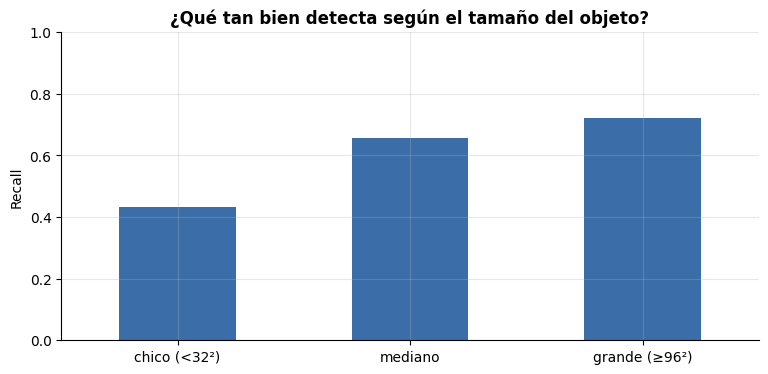

In [15]:
def gt_detectados(preds, iou_thr=0.5):
    """Marca cada objeto real como detectado o no (mismo emparejamiento que evaluar_cajas)."""
    grupos = {k: g.sort_values("score", ascending=False).bbox.tolist()
              for k, g in preds.groupby(["image_id", "category_id"])}
    filas = []
    for (img_id, c), gts in gt_by.items():
        usado = [False] * len(gts)
        for b in grupos.get((img_id, c), []):
            ious = [-1 if usado[k] else iou_xywh(b, g) for k, g in enumerate(gts)]
            k = int(np.argmax(ious))
            if ious[k] >= iou_thr:
                usado[k] = True
        filas += [(img_id, c, g[2] * g[3], u) for g, u in zip(gts, usado)]
    return pd.DataFrame(filas, columns=["image_id", "category_id", "area", "detectado"])

sel = dets_nms[dets_nms.score >= UMBRAL]
gd = gt_detectados(sel)
gd["tamaño"] = pd.cut(gd.area, [0, 32**2, 96**2, np.inf], labels=["chico (<32²)", "mediano", "grande (≥96²)"])
print("Recall por tamaño del objeto:")
print(gd.groupby("tamaño", observed=True).detectado.agg(["count", "mean"]).rename(columns={"count": "objetos", "mean": "recall"}).round(3))

res, tabla = evaluar_cajas(sel, detalle=True)
tabla["recall"] = tabla.TP / (tabla.TP + tabla.FN).replace(0, np.nan)
print("\nLas 10 clases con peor recall (con al menos 5 objetos reales):")
print(tabla[(tabla.TP + tabla.FN) >= 5].sort_values("recall").head(10)[["TP", "FN", "recall"]].round(2))
print("\nLas 10 clases con más falsos positivos:")
print(tabla.sort_values("FP", ascending=False).head(10)[["TP", "FP", "FN"]])

ax = gd.groupby("tamaño", observed=True).detectado.mean().plot.bar(color=AZUL, rot=0)
ax.set(title="¿Qué tan bien detecta según el tamaño del objeto?", xlabel="", ylabel="Recall", ylim=(0, 1))
plt.show()

### 2.6 Diagnóstico: ¿por qué casi no detecta personas?
`person` tiene recall 0,03, algo raro para OWLv2. Hipótesis: el post-procesado estándar asigna **una sola clase por caja** (la de mayor puntaje). Una persona puede competir con clases que la cubren, como prendas de ropa, y perder. Para cada persona real buscamos la caja predicha que mejor la cubre y miramos qué clase recibió.

In [16]:
def clase_asignada(nombre):
    """Para cada objeto real de la clase, qué clase tiene la caja cruda (umbral 0,05) que mejor lo cubre."""
    cid = cats.set_index("category_name").category_id[nombre]
    res = []
    for (img_id, c), gts in gt_by.items():
        if c != cid:
            continue
        d_img = dets[dets.image_id == img_id]
        for g in gts:
            ious = d_img.bbox.map(lambda b: iou_xywh(b, g))
            m = d_img[ious >= 0.5]
            res.append(id2name[m.loc[m.score.idxmax(), "category_id"]] if len(m) else "(ninguna caja)")
    return pd.Series(res).value_counts()

for nombre in ["person", "book", "shoe"]:
    print(f"--- {nombre}: clase que recibe la mejor caja ---")
    print(clase_asignada(nombre).head(6).to_string(), "\n")

--- person: clase que recibe la mejor caja ---
person     17
shirt       5
jacket      3
bed         1
book        1
bicycle     1 

--- book: clase que recibe la mejor caja ---
(ninguna caja)    26
book              17
cell phone         1
handle             1
box                1 

--- shoe: clase que recibe la mejor caja ---
shoe              27
(ninguna caja)     3
boot               1 



**Resultado del diagnóstico:** de 29 personas, 17 tienen una caja etiquetada `person` pero con confianza baja (no superan el umbral 0,2), y 8 perdieron la etiqueta contra `shirt` o `jacket`. En `book`, 26 de 43 no tienen ninguna caja: es el problema de los objetos chicos (1.3).

### 2.7 Experimento controlado: una etiqueta por caja vs. varias
**Variable que cambiamos:** cuántas clases puede recibir cada caja predicha (k = 1, 2 o 3, las de mayor puntaje). **Fijo:** modelo, prompts, resolución, NMS 0,5 y la métrica.
Hipótesis: con k > 1 recuperamos objetos que pierden contra clases que se solapan (persona vs. ropa), a costa de algunos falsos positivos.
Control: con k = 1 tenemos que reproducir la línea base (F1 = 0,646).

33294 detecciones crudas en 0.9 min

Mejor F1 de cada variante:
 k  umbral     P     R    F1   TP  FP  FN  cobertura
 1     0.2 0.732 0.578 0.646 1035 378 755      0.463
 2     0.2 0.724 0.606 0.660 1084 413 706      0.431
 3     0.2 0.724 0.608 0.661 1089 415 701      0.429


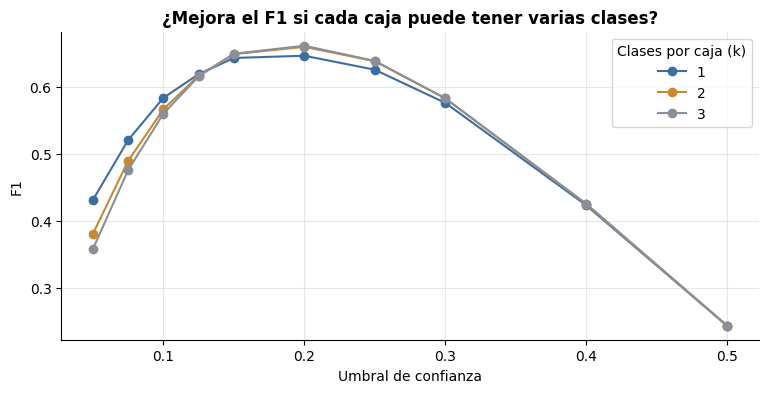

In [17]:
@torch.no_grad()
def detectar_multi(img_path, umbral=0.05, k_max=3):
    """Como detectar(), pero cada caja puede recibir hasta k_max clases. Recibe SÓLO la imagen y el vocabulario."""
    im = Image.open(img_path).convert("RGB")
    W, H = im.size
    inp = processor(text=[PROMPTS], images=im, return_tensors="pt").to(device)
    out = model(**inp)
    probs = out.logits[0].sigmoid()           # (cajas, clases)
    top_p, top_c = probs.topk(k_max, dim=1)   # las k clases con mayor puntaje por caja
    cajas = out.pred_boxes[0].tolist()        # (cx, cy, w, h) normalizadas al cuadrado rellenado
    S = max(W, H)
    filas = []
    for i, rango in (top_p >= umbral).nonzero().tolist():
        cx, cy, w, h = [v * S for v in cajas[i]]
        x1, y1, x2, y2 = max(0, cx - w / 2), max(0, cy - h / 2), min(W, cx + w / 2), min(H, cy + h / 2)
        if x2 > x1 and y2 > y1:
            filas.append(dict(category_id=CAT_IDS[top_c[i, rango].item()], score=top_p[i, rango].item(),
                              bbox=[x1, y1, x2 - x1, y2 - y1], rango=rango))
    return filas

filas = []
t0 = time.time()
for img_id, fname in imgs[["id", "fname"]].itertuples(index=False):
    for d in detectar_multi(DEV / "images" / fname):
        d["image_id"] = img_id
        filas.append(d)
dets_multi = pd.DataFrame(filas)
dets_multi.to_pickle(SALIDA / "dets_owlv2_base_dev_top3.pkl")
print(f"{len(dets_multi)} detecciones crudas en {(time.time() - t0) / 60:.1f} min")

resultados = []
for k in (1, 2, 3):
    dk = aplicar_nms(dets_multi[dets_multi.rango < k])
    for u in umbrales:
        resultados.append(dict(k=k, umbral=u, **evaluar_cajas(dk[dk.score >= u])))
exp = pd.DataFrame(resultados)
resumen = exp.loc[exp.groupby("k").F1.idxmax(), ["k", "umbral", "P", "R", "F1", "TP", "FP", "FN", "cobertura"]]
print("\nMejor F1 de cada variante:")
print(resumen.round(3).to_string(index=False))

ax = exp.pivot(index="umbral", columns="k", values="F1").plot(marker="o", color=[AZUL, "#c98a2b", GRIS])
ax.set(title="¿Mejora el F1 si cada caja puede tener varias clases?", xlabel="Umbral de confianza", ylabel="F1")
ax.legend(title="Clases por caja (k)"); plt.show()

### 2.8 Conclusiones de la Fase 2

| Configuración | Umbral | P | R | F1 | TP | FP | FN |
|---|---|---|---|---|---|---|---|
| OWLv2 base, sin NMS | 0,20 | | | 0,633 | | | |
| Línea base: OWLv2 base + NMS 0,5, 1 clase por caja | 0,20 | 0,732 | 0,578 | 0,646 | 1035 | 378 | 755 |
| **Elegida: 2 clases por caja** | 0,20 | 0,724 | 0,606 | **0,660** | 1084 | 413 | 706 |
| 3 clases por caja | 0,20 | 0,724 | 0,608 | 0,661 | 1089 | 415 | 701 |

**Lectura del experimento.** Permitir varias clases por caja recupera 49 objetos reales a cambio de 35 falsos positivos más, y sube el F1 en 1,4 puntos. Elegimos **k = 2**: k = 3 casi no agrega (+0,001) y genera más detecciones. El control con k = 1 reprodujo exactamente la línea base, así que la mejora se debe sólo a la variable cambiada. El umbral óptimo se mantuvo en 0,20 en las tres variantes.

**Qué sigue limitando el resultado:**
- **Recall bajo en objetos chicos:** 0,43 en chicos contra 0,72 en grandes. En `book`, 26 de 43 objetos no tienen ninguna caja. Candidato a experimento: OWLv2 *large* o mayor resolución de entrada.
- **Confianzas no calibradas entre clases:** `person` y `shoe` se detectan pero con puntaje bajo, y un umbral único los deja afuera. Un umbral por clase ajustado con sólo 120 imágenes tendría riesgo alto de sobreajuste, así que lo dejamos como limitación documentada.
- **Falsos positivos concentrados** en clases parecidas entre sí (`ski`, `streetlight`, `knife`, `traffic light`).

**Configuración que pasa a la Fase 3:** OWLv2 base, prompt `"a photo of a {clase}"`, hasta 2 clases por caja, NMS por clase 0,5 y umbral 0,20.

*Nota:* estas métricas son locales (F1 micro con reglas LVIS). El valor oficial se confirma con el primer envío a Kaggle.

## 3. Segmentación (SAM2) y propiedades derivadas

El detector dice **qué es y dónde está, aproximadamente** (caja). SAM2 dice **exactamente qué píxeles** ocupa, pero no sabe qué es: necesita que le pasemos la caja como prompt. Por eso va segundo en la pipeline.

De la máscara salen las propiedades **derivadas** del SceneJSON: `centroid`, `area_ratio`, `position` (grilla 3×3) y `size`; y entre pares de objetos, las `relations`.

### 3.1 Carga de SAM2 y prueba con una imagen

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  184MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/357 [00:00<?, ?it/s]

Segmentador: facebook/sam2.1-hiera-small
Detecciones finales en desarrollo: 3477 (umbral 0.2)
51 máscaras en 0.75 s | forma (480, 640) | imagen 480x640


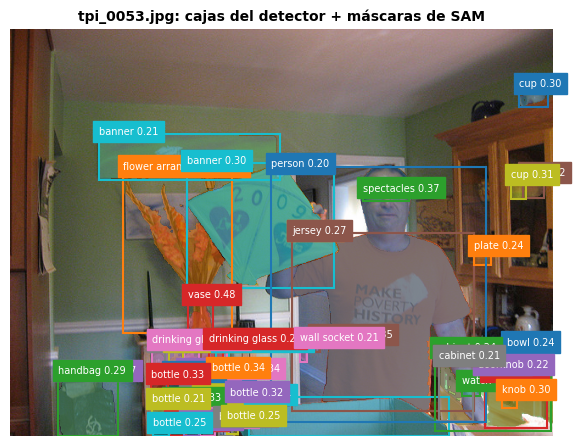

In [18]:
try:
    from transformers import Sam2Processor, Sam2Model
    SAM_ID = "facebook/sam2.1-hiera-small"
    sam_proc = Sam2Processor.from_pretrained(SAM_ID)
    sam = Sam2Model.from_pretrained(SAM_ID).to(device).eval()
    ES_SAM2 = True
except Exception as e:  # respaldo si esta versión de transformers no trae SAM2
    print("SAM2 no disponible, uso SAM v1:", repr(e)[:200])
    from transformers import SamProcessor, SamModel
    SAM_ID = "facebook/sam-vit-base"
    sam_proc = SamProcessor.from_pretrained(SAM_ID)
    sam = SamModel.from_pretrained(SAM_ID).to(device).eval()
    ES_SAM2 = False
print("Segmentador:", SAM_ID)

@torch.no_grad()
def segmentar(im, cajas_xywh, lote=64):
    """Recibe la imagen y las cajas del detector. Devuelve una máscara booleana (H, W) por caja."""
    mascaras = []
    for i in range(0, len(cajas_xywh), lote):
        xyxy = [[x, y, x + w, y + h] for x, y, w, h in cajas_xywh[i:i + lote]]
        inp = sam_proc(images=im, input_boxes=[xyxy], return_tensors="pt").to(device)
        out = sam(**inp, multimask_output=False)
        if ES_SAM2:
            m = sam_proc.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu())[0]
        else:
            m = sam_proc.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu(), inp["reshaped_input_sizes"].cpu())[0]
        mascaras += [mm[0].numpy().astype(bool) for mm in m]
    return mascaras

# Detecciones finales de la Fase 2: hasta 2 clases por caja, NMS 0,5, umbral 0,20
dk = aplicar_nms(dets_multi[dets_multi.rango < 2])
dets_final = dk[dk.score >= UMBRAL].reset_index(drop=True)
print(f"Detecciones finales en desarrollo: {len(dets_final)} (umbral {UMBRAL})")

# Prueba con la imagen de la verificación visual 1.9 (11 objetos)
img_id = elegidas[1]
info = img_meta[img_id]
im = Image.open(DEV / "images" / info.fname).convert("RGB")
d_img = dets_final[dets_final.image_id == img_id]
t0 = time.time()
masks = segmentar(im, d_img.bbox.tolist())
print(f"{len(masks)} máscaras en {time.time() - t0:.2f} s | forma {masks[0].shape} | imagen {info.height}x{info.width}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(im); ax.axis("off")
colores = plt.cm.tab10(np.arange(len(masks)) % 10)
for m, (_, d), col in zip(masks, d_img.iterrows(), colores):
    capa = np.zeros((*m.shape, 4)); capa[m] = [*col[:3], 0.45]
    ax.imshow(capa)
    x, y, w, h = d.bbox
    ax.add_patch(Rectangle((x, y), w, h, fill=False, ec=col, lw=1.5))
    ax.text(x, y, f"{id2name[d.category_id]} {d.score:.2f}", fontsize=7, color="white", backgroundcolor=col)
ax.set_title(f"{info.fname}: cajas del detector + máscaras de SAM", fontsize=10)
plt.show()

### 3.2 Codificación RLE y test de ida y vuelta
El schema pide la máscara como RLE **no comprimido**: `{"size": [alto, ancho], "counts": [...]}`, donde `counts` son largos de corridas alternadas que **arrancan contando ceros**. El `size` en orden `[alto, ancho]` es la convención de COCO (lo confirma `sample_submission.csv`), así que usamos también su orden de aplanado: **por columnas** (Fortran).

Un error acá deja el F1 de máscaras casi en 0 aunque las máscaras sean perfectas, por eso lo testeamos tres veces: contra el ejemplo oficial, con máscaras al azar y contra `pycocotools`.

In [19]:
from pycocotools import mask as mask_utils

def rle_encode(mask):
    """Máscara booleana (H, W) -> RLE no comprimido estilo COCO (por columnas, arranca contando ceros)."""
    v = mask.ravel(order="F").astype(np.uint8)
    cambios = np.flatnonzero(np.diff(v)) + 1
    counts = np.diff(np.concatenate([[0], cambios, [v.size]])).tolist()
    if v[0] == 1:
        counts = [0] + counts
    return {"size": [int(mask.shape[0]), int(mask.shape[1])], "counts": counts}

def rle_decode(rle):
    h, w = rle["size"]
    v = np.zeros(h * w, dtype=bool)
    pos, valor = 0, False
    for c in rle["counts"]:
        if valor:
            v[pos:pos + c] = True
        pos += c
        valor = not valor
    return v.reshape((h, w), order="F")

# Test 1: el ejemplo oficial de sample_submission (un solo píxel en la esquina)
ej = json.loads(sub.iloc[0].SceneJSON)["objects"][0]["mask"]
m_ej = rle_decode(ej)
print("Test 1 | píxeles en 1:", m_ej.sum(), "| en (0,0):", m_ej[0, 0], "| re-codifica igual:", rle_encode(m_ej) == ej)

# Test 2: ida y vuelta con 200 máscaras al azar, incluso las que arrancan en 1 o están vacías
rng = np.random.default_rng(0)
ok = all(np.array_equal(rle_decode(rle_encode(m)), m)
         for m in [rng.random((rng.integers(1, 60), rng.integers(1, 60))) < rng.random() for _ in range(200)])
print("Test 2 | ida y vuelta en 200 máscaras al azar:", ok)

# Test 3: pycocotools tiene que leer nuestro RLE y obtener la misma máscara (mismo orden de píxeles)
ok3 = True
for m in masks[:10]:
    r = rle_encode(m)
    dec = mask_utils.decode(mask_utils.frPyObjects(r, *r["size"]))
    ok3 &= np.array_equal(dec.astype(bool), m)
print("Test 3 | pycocotools decodifica igual (10 máscaras de SAM):", ok3)
largo = np.mean([len(rle_encode(m)["counts"]) for m in masks])
print(f"Largo medio de counts: {largo:.0f} números por máscara (contra {masks[0].size} píxeles)")

Test 1 | píxeles en 1: 1 | en (0,0): True | re-codifica igual: True
Test 2 | ida y vuelta en 200 máscaras al azar: True
Test 3 | pycocotools decodifica igual (10 máscaras de SAM): True
Largo medio de counts: 124 números por máscara (contra 307200 píxeles)


### 3.3 Segmentación de las 120 imágenes y F1 de máscaras
Segmentamos todas las detecciones finales de la Fase 2 y medimos el F1 de máscaras con las mismas reglas LVIS, pero con IoU entre máscaras.

**Experimento controlado:** comparamos SAM2 contra una línea base trivial que usa **la caja rellena como máscara**. Mismo detector, mismas detecciones, misma métrica: sólo cambia de dónde sale la máscara. Si SAM2 no le gana a la caja, no está aportando nada.

In [20]:
# Máscaras reales: polígonos de annotations.json -> RLE de pycocotools (sólo para evaluar)
gt_rle = defaultdict(list)
for a in ann["annotations"]:
    r = img_meta[a["image_id"]]
    gt_rle[(a["image_id"], a["category_id"])].append(
        mask_utils.merge(mask_utils.frPyObjects(a["segmentation"], r.height, r.width)))

def a_rle_coco(rle):
    """Acepta nuestro RLE no comprimido o uno ya comprimido por pycocotools."""
    return mask_utils.frPyObjects(rle, *rle["size"]) if isinstance(rle["counts"], list) else rle

def evaluar_mascaras(preds, col="rle", iou_thr=0.5):
    """Mismas reglas LVIS que evaluar_cajas, pero con IoU entre máscaras."""
    grupos = {k: g.sort_values("score", ascending=False)[col].tolist()
              for k, g in preds.groupby(["image_id", "category_id"])}
    cats_pred = defaultdict(set)
    for i, c in grupos:
        cats_pred[i].add(c)
    tp = fp = fn = ign = 0
    for img_id, r in img_meta.items():
        neg, noexh = set(r.neg_category_ids), set(r.not_exhaustive_category_ids)
        for c in pos.get(img_id, set()) | cats_pred[img_id]:
            pm, gts = grupos.get((img_id, c), []), gt_rle.get((img_id, c), [])
            if gts:
                usado = np.zeros(len(gts), bool)
                if pm:
                    M = np.atleast_2d(mask_utils.iou([a_rle_coco(m) for m in pm], gts, [0] * len(gts)))
                    for i in range(len(pm)):
                        fila = np.where(usado, -1, M[i])
                        k = int(np.argmax(fila))
                        if fila[k] >= iou_thr:
                            usado[k] = True; tp += 1
                        elif c in noexh:
                            ign += 1
                        else:
                            fp += 1
                fn += int((~usado).sum())
            elif c in neg:
                fp += len(pm)
            else:
                ign += len(pm)
    P = tp / (tp + fp) if tp + fp else 0.0
    R = tp / (tp + fn) if tp + fn else 0.0
    return dict(P=P, R=R, F1=2 * P * R / (P + R) if P + R else 0.0, TP=tp, FP=fp, FN=fn, ignoradas=ign)

gt_pred = pd.DataFrame([dict(image_id=i, category_id=c, score=1.0, rle=m) for (i, c), ms in gt_rle.items() for m in ms])
print("Cordura | máscaras reales como predicción (esperado F1 = 1):", round(evaluar_mascaras(gt_pred)["F1"], 3))

def caja_a_mascara(b, H, W):
    m = np.zeros((H, W), bool)
    x, y, w, h = b
    m[int(round(y)):int(round(y + h)), int(round(x)):int(round(x + w))] = True
    return m

rle_sam, rle_caja, vacias = {}, {}, 0
t0 = time.time()
for img_id, d_img in dets_final.groupby("image_id", sort=False):
    r = img_meta[img_id]
    im = Image.open(DEV / "images" / r.fname).convert("RGB")
    for idx, b, m in zip(d_img.index, d_img.bbox, segmentar(im, d_img.bbox.tolist())):
        mc = caja_a_mascara(b, r.height, r.width)
        if m.sum() == 0:  # SAM no devolvió píxeles: usamos la caja como respaldo
            m, vacias = mc, vacias + 1
        rle_sam[idx], rle_caja[idx] = rle_encode(m), rle_encode(mc)
dets_final["rle_sam"] = pd.Series(rle_sam)
dets_final["rle_caja"] = pd.Series(rle_caja)
print(f"{len(dets_final)} máscaras en {(time.time() - t0) / 60:.1f} min | máscaras vacías reemplazadas por la caja: {vacias}")
dets_final.to_pickle(SALIDA / "dets_final_dev_con_mascaras.pkl")

comp = pd.DataFrame([dict(fuente="Caja como máscara (línea base)", **evaluar_mascaras(dets_final, "rle_caja")),
                     dict(fuente="SAM2 con la caja como prompt", **evaluar_mascaras(dets_final, "rle_sam"))])
print("\nF1 de máscaras (IoU de máscara ≥ 0,5):")
print(comp.round(3).to_string(index=False))
print("\nReferencia, F1 de cajas de las mismas detecciones:", round(evaluar_cajas(dets_final)["F1"], 3))

Cordura | máscaras reales como predicción (esperado F1 = 1): 1.0
3477 máscaras en 0.8 min | máscaras vacías reemplazadas por la caja: 0

F1 de máscaras (IoU de máscara ≥ 0,5):
                        fuente     P     R    F1   TP  FP   FN  ignoradas
Caja como máscara (línea base) 0.470 0.383 0.422  686 774 1104       2017
  SAM2 con la caja como prompt 0.682 0.568 0.620 1016 474  774       1987

Referencia, F1 de cajas de las mismas detecciones: 0.66


### 3.4 Propiedades derivadas y relaciones espaciales
Estas propiedades **no las predice ningún modelo**: se calculan con código a partir de la máscara. Son *derivadas* y por eso son auditables.

| Campo | Regla |
|---|---|
| `centroid` | promedio de las coordenadas (x, y) de los píxeles de la máscara |
| `area_ratio` | píxeles de la máscara / píxeles de la imagen |
| `position` | celda de la grilla 3×3 donde cae el centroide |
| `size` | umbrales de COCO sobre el área en píxeles: `small` < 32², `medium` < 96², `large` ≥ 96² |
| `left_of` / `right_of` | diferencia horizontal de centroides mayor al 5 % del ancho |
| `above` / `below` | diferencia vertical de centroides mayor al 5 % del alto (y crece hacia abajo) |
| `overlaps` | IoU entre máscaras > 0,01 (simétrica) |

El margen del 5 % evita relaciones ruidosas entre objetos casi alineados. Los umbrales de `size` no están en el enunciado: usamos los de COCO porque el dataset deriva de COCO/LVIS y los documentamos como decisión propia.

In [21]:
POS = [["top_left", "top_center", "top_right"],
       ["middle_left", "center", "middle_right"],
       ["bottom_left", "bottom_center", "bottom_right"]]

def propiedades(mask, W, H):
    """Propiedades DERIVADAS de la máscara (las calcula código, no un modelo)."""
    ys, xs = np.nonzero(mask)
    cx, cy, area = float(xs.mean()), float(ys.mean()), len(xs)
    fila, col = min(int(cy / (H / 3)), 2), min(int(cx / (W / 3)), 2)
    tam = "small" if area < 32**2 else ("medium" if area < 96**2 else "large")
    return dict(centroid=[round(cx, 1), round(cy, 1)], area_ratio=area / (W * H), position=POS[fila][col], size=tam)

def relaciones(objs_img, W, H, margen=0.05, iou_min=0.01):
    """Relaciones entre todos los pares de objetos. objs_img: lista de dicts con id, centroid y rle."""
    rels = []
    for a in objs_img:
        for b in objs_img:
            if a["id"] == b["id"]:
                continue
            (ax, ay), (bx, by) = a["centroid"], b["centroid"]
            if ax < bx - margen * W: rels.append(dict(subject=a["id"], predicate="left_of", object=b["id"]))
            if ax > bx + margen * W: rels.append(dict(subject=a["id"], predicate="right_of", object=b["id"]))
            if ay < by - margen * H: rels.append(dict(subject=a["id"], predicate="above", object=b["id"]))
            if ay > by + margen * H: rels.append(dict(subject=a["id"], predicate="below", object=b["id"]))
    if len(objs_img) > 1:
        R = [a_rle_coco(o["rle"]) for o in objs_img]
        M = np.atleast_2d(mask_utils.iou(R, R, [0] * len(R)))
        for i, j in zip(*np.nonzero(M > iou_min)):
            if i != j:
                rels.append(dict(subject=objs_img[i]["id"], predicate="overlaps", object=objs_img[j]["id"]))
    return rels

# Calculamos todo sobre las 120 imágenes de desarrollo
filas, n_objs, n_rels, ejemplo = [], [], [], None
for img_id, d_img in dets_final.groupby("image_id"):
    r = img_meta[img_id]
    objs_img = []
    for k, (_, d) in enumerate(d_img.sort_values("score", ascending=False).iterrows(), 1):
        p = propiedades(rle_decode(d.rle_sam), r.width, r.height)
        objs_img.append(dict(id=f"obj_{k}", category=id2name[d.category_id], rle=d.rle_sam, **p))
        filas.append(p)
    rels = relaciones(objs_img, r.width, r.height)
    n_objs.append(len(objs_img)); n_rels.append(len(rels))
    if img_id == elegidas[1]:
        ejemplo = (objs_img, rels)
props = pd.DataFrame(filas)

gt_size = pd.cut(objs.area, [0, 32**2, 96**2, np.inf], right=False, labels=["small", "medium", "large"])
print("Distribución de size: predicho vs. real")
print(pd.DataFrame({"predicho": props["size"].value_counts(normalize=True), "real (EDA 1.3)": gt_size.value_counts(normalize=True)}).round(2))
print(f"\nObjetos por imagen: máx {max(n_objs)} (límite del schema 300) | relaciones por imagen: media {np.mean(n_rels):.0f}, máx {max(n_rels)} (límite 20000)")

objs_ej, rels_ej = ejemplo
print(f"\nEjemplo ({img_meta[elegidas[1]].fname}): 5 objetos y 6 relaciones")
print(pd.DataFrame(objs_ej)[["id", "category", "centroid", "area_ratio", "position", "size"]].head(5).round(4).to_string(index=False))
print(pd.DataFrame(rels_ej).head(6).to_string(index=False))

Distribución de size: predicho vs. real
        predicho  real (EDA 1.3)
small       0.49            0.54
medium      0.38            0.33
large       0.13            0.13

Objetos por imagen: máx 88 (límite del schema 300) | relaciones por imagen: media 1904, máx 13318 (límite 20000)

Ejemplo (tpi_0053.jpg): 5 objetos y 6 relaciones
   id           category       centroid  area_ratio      position   size
obj_1               kite [297.3, 230.4]      0.0480        center  large
obj_2 flower arrangement [206.1, 262.1]      0.0215   middle_left medium
obj_3              watch [543.6, 425.7]      0.0006  bottom_right  small
obj_4               vase [224.3, 342.4]      0.0022 bottom_center  small
obj_5        plastic bag  [89.5, 446.2]      0.0141   bottom_left medium
subject predicate object
  obj_1  right_of  obj_2
  obj_1     above  obj_2
  obj_1   left_of  obj_3
  obj_1     above  obj_3
  obj_1  right_of  obj_4
  obj_1     above  obj_4


### 3.5 Conclusiones de la Fase 3

**RLE verificado.** El formato `{"size": [alto, ancho], "counts": [...]}` aplanado **por columnas** pasó los tres tests: el ejemplo oficial, 200 máscaras al azar y la decodificación de `pycocotools`. Queda resuelta la duda del EDA sobre el orden del RLE.

**Experimento controlado: ¿de dónde sale la máscara?** Mismas 3477 detecciones, misma métrica.

| Fuente de la máscara | P | R | F1 máscaras | TP | FP | FN |
|---|---|---|---|---|---|---|
| Caja rellena (línea base) | 0,470 | 0,383 | 0,422 | 686 | 774 | 1104 |
| **SAM2 (hiera-small) con la caja como prompt** | 0,682 | 0,568 | **0,620** | 1016 | 474 | 774 |

SAM2 sube el F1 de máscaras **20 puntos** sobre la caja: recupera 330 objetos que la caja no alcanza a cubrir con IoU ≥ 0,5. Frente al F1 de cajas (0,660) se pierden sólo 4 puntos. Eso indica que el cuello de botella sigue siendo el **detector**, no la segmentación: si la caja es buena, SAM2 casi siempre acierta la máscara. Ninguna máscara salió vacía (el respaldo con la caja quedó sin usar).

**Propiedades.** La distribución de `size` predicha (49 % / 38 % / 13 %) es parecida a la real del EDA (54 % / 33 % / 13 %). En el ejemplo revisado, posiciones y relaciones coinciden con la imagen: el barrilete en `center` está `above` y `right_of` el arreglo floral.

**Riesgo detectado para la Fase 4:** la imagen más cargada tiene 88 objetos y genera **13 318 relaciones**, cerca del límite de 20 000 del schema. Como crecen con el cuadrado de los objetos, una imagen de test con ~110 objetos lo pasaría. Al armar el SceneJSON vamos a poner un tope: si se supera, se calculan relaciones sólo entre los objetos de mayor confianza.

**Pendiente de la Fase 4:** armar el SceneJSON completo, validarlo con `jsonschema`, guardar la traza por módulo y hacer el **primer envío** para confirmar con la métrica oficial el formato y el orden del RLE.

## 4. SceneJSON, traza y primer envío

Juntamos las Fases 2 y 3 en **una sola función `procesar_imagen()`** que recibe sólo la imagen y devuelve el SceneJSON. Es la pipeline que se evalúa: no lee anotaciones, así que se puede probar con fotos nuevas.

```
imagen -> detector (OWLv2, 2 clases por caja) -> NMS + umbral 0,20 -> SAM2 -> propiedades -> relaciones -> validación -> SceneJSON
```

**Topes para respetar el schema:** como máximo 300 objetos (los de mayor confianza). Si las relaciones pasan de 20 000, se recalculan con el 90 % de los objetos más confiables, hasta quedar debajo del límite.

**Traza:** cada módulo registra qué corrió, con qué parámetros, cuánto tardó, si falló y cuántas salidas produjo. Si una imagen falla, la traza dice en qué módulo, y esa fila sale con una escena vacía pero válida en lugar de romper el envío.

### 4.1 La pipeline completa

In [22]:
import jsonschema

schema = json.load(open(ROOT / "scene_schema.json"))
validador = jsonschema.Draft202012Validator(schema)
MAX_OBJ = schema["properties"]["objects"]["maxItems"]      # 300
MAX_REL = schema["properties"]["relations"]["maxItems"]    # 20000
print("Topes del schema:", MAX_OBJ, "objetos y", MAX_REL, "relaciones")

def paso(traza, image_id, modulo, params, fn):
    """Ejecuta un módulo y deja registro en la traza (tiempo, parámetros, error, cantidad de salidas)."""
    t0, inicio = time.time(), time.strftime("%H:%M:%S")
    fila = dict(image_id=image_id, modulo=modulo, params=json.dumps(params, ensure_ascii=False), inicio=inicio)
    try:
        out = fn()
        n = len(out[0]) if isinstance(out, tuple) else (len(out) if hasattr(out, "__len__") else 1)
        traza.append(dict(fila, duracion_ms=round((time.time() - t0) * 1000, 1), ok=True, n_salidas=n, error=""))
        return out
    except Exception as e:
        traza.append(dict(fila, duracion_ms=round((time.time() - t0) * 1000, 1), ok=False, n_salidas=0, error=repr(e)[:300]))
        raise

def caja_xyxy(b, W, H):
    """[x, y, ancho, alto] (formato interno, COCO) -> [xmin, ymin, xmax, ymax] (formato que exige la métrica)."""
    x, y, w, h = [float(v) for v in b]
    return [round(max(0.0, x), 2), round(max(0.0, y), 2), round(min(float(W), x + w), 2), round(min(float(H), y + h), 2)]

def caja_valida(b):
    return 0 <= b[0] < b[2] and 0 <= b[1] < b[3]

def relaciones_con_tope(objetos, W, H):
    """Si hay demasiadas relaciones, recalcula con el 90 % de los objetos más confiables hasta respetar el límite."""
    base = [dict(o, rle=o["mask"]) for o in objetos]  # ya vienen ordenados por confianza
    n = len(base)
    while True:
        rels = relaciones(base[:n], W, H)
        if len(rels) <= MAX_REL:
            return rels, n
        n = int(n * 0.9)

def escena_vacia(image_id, W, H):
    return dict(image=dict(id=image_id, width=W, height=H), objects=[], relations=[], questions=[], questions_llm=[])

def procesar_imagen(path, image_id, traza):
    """PIPELINE COMPLETA. Recibe SÓLO la imagen y el vocabulario: nunca lee anotaciones."""
    im = Image.open(path).convert("RGB")
    W, H = im.size
    try:
        crudas = paso(traza, image_id, "detector", dict(modelo=MODELO, prompt="a photo of a {clase}", k_max=2, umbral_crudo=0.05),
                      lambda: pd.DataFrame(detectar_multi(path, umbral=0.05, k_max=2)))
        if len(crudas):
            crudas["image_id"] = image_id
            finales = paso(traza, image_id, "nms_umbral", dict(nms_iou=0.5, umbral=UMBRAL, max_obj=MAX_OBJ),
                           lambda: (lambda d: d[d.score >= UMBRAL])(aplicar_nms(crudas))
                           .sort_values("score", ascending=False).head(MAX_OBJ).reset_index(drop=True))
        else:
            finales = crudas
        masks = paso(traza, image_id, "segmentador", dict(modelo=SAM_ID),
                     lambda: segmentar(im, finales.bbox.tolist()) if len(finales) else [])
        objetos = []
        def armar_objetos():
            for d, m in zip(finales.itertuples(), masks):
                caja = caja_xyxy(d.bbox, W, H)
                if not caja_valida(caja):
                    continue                           # caja degenerada (ancho o alto 0 tras recortar al borde)
                if m.sum() == 0:
                    m = caja_a_mascara(d.bbox, H, W)   # respaldo: la caja como máscara
                if m.sum() == 0:
                    continue
                objetos.append(dict(id=f"obj_{len(objetos) + 1}", category_id=int(d.category_id),
                                    category_name=id2name[d.category_id], confidence=round(float(d.score), 4),
                                    bbox=caja, mask=rle_encode(m), **propiedades(m, W, H)))
            return objetos
        paso(traza, image_id, "propiedades", dict(bbox="xyxy", size="COCO 32^2 / 96^2", grilla="3x3 por centroide"), armar_objetos)
        rels, n_usados = paso(traza, image_id, "relaciones", dict(margen=0.05, iou_overlaps=0.01, max_rel=MAX_REL),
                              lambda: relaciones_con_tope(objetos, W, H))
        escena = dict(image=dict(id=image_id, width=W, height=H), objects=objetos, relations=rels, questions=[], questions_llm=[])
        errores = paso(traza, image_id, "validacion", dict(schema="scene_schema.json", regla_bbox="0<=xmin<xmax, 0<=ymin<ymax"),
                       lambda: [e.message for e in validador.iter_errors(escena)]
                               + [f"bbox inválida en {o['id']}" for o in objetos if not caja_valida(o["bbox"])])
        if errores:
            raise ValueError(f"SceneJSON inválido: {errores[:2]}")
        return escena
    except Exception as e:
        print(f"[{image_id}] falló, se envía una escena vacía válida: {repr(e)[:150]}")
        return escena_vacia(image_id, W, H)

# Prueba con una imagen de desarrollo
traza_prueba = []
r = img_meta[elegidas[1]]
esc = procesar_imagen(DEV / "images" / r.fname, Path(r.fname).stem, traza_prueba)
texto = json.dumps(esc, separators=(",", ":"))
print(f"{len(esc['objects'])} objetos | {len(esc['relations'])} relaciones | JSON de {len(texto) / 1024:.0f} KB | válido: {validador.is_valid(esc)}")
print("Cajas que cumplen 0 <= xmin < xmax y 0 <= ymin < ymax:", sum(caja_valida(o["bbox"]) for o in esc["objects"]), "de", len(esc["objects"]))
print(pd.DataFrame(traza_prueba)[["modulo", "duracion_ms", "ok", "n_salidas"]].to_string(index=False))
print(json.dumps({**esc["objects"][0], "mask": "..."}, ensure_ascii=False))

Topes del schema: 300 objetos y 20000 relaciones
51 objetos | 4168 relaciones | JSON de 278 KB | válido: True
Cajas que cumplen 0 <= xmin < xmax y 0 <= ymin < ymax: 51 de 51
     modulo  duracion_ms   ok  n_salidas
   detector        524.7 True        353
 nms_umbral          3.0 True         51
segmentador        426.2 True         51
propiedades        109.7 True         51
 relaciones          3.6 True       4168
 validacion        162.6 True          0
{"id": "obj_1", "category_id": 87, "category_name": "kite", "confidence": 0.5959, "bbox": [208.01, 157.89, 381.33, 304.68], "mask": "...", "centroid": [297.3, 230.4], "area_ratio": 0.048040364583333335, "position": "center", "size": "large"}


### 4.2 Armado del archivo de envío (80 filas)
Corremos `procesar_imagen()` sobre las 80 imágenes de `sample_submission.csv`, en el mismo orden: 60 de test y 20 de desarrollo. Antes de guardar verificamos que haya 80 filas en el mismo orden, que todos los SceneJSON pasen el schema y cuánto pesa el archivo.

**Chequeo de serialización:** en las 20 filas de desarrollo volvemos a leer el CSV, reconstruimos las predicciones desde el JSON y las medimos. Tienen que dar exactamente lo mismo que las detecciones de la Fase 3 sobre esas imágenes; si no, algo se rompió al escribir el JSON.

In [23]:
rutas = {p.stem: p for p in ROOT.rglob("*.jpg")}
faltan = [i for i in sub.image_id if i not in rutas]
print("Imágenes del envío sin archivo encontrado:", faltan or "ninguna")
print("test_images.csv:", list(pd.read_csv(TEST / "test_images.csv").columns))

traza, filas_env = [], []
t0 = time.time()
for iid in sub.image_id:
    esc = procesar_imagen(rutas[iid], iid, traza)
    filas_env.append(dict(image_id=iid, SceneJSON=json.dumps(esc, separators=(",", ":"), ensure_ascii=False)))
envio = pd.DataFrame(filas_env)
traza = pd.DataFrame(traza)
print(f"\n80 imágenes procesadas en {(time.time() - t0) / 60:.1f} min")

# Verificaciones antes de guardar
assert list(envio.columns) == ["image_id", "SceneJSON"] and list(envio.image_id) == list(sub.image_id), "filas u orden distintos al sample"
escenas = [json.loads(s) for s in envio.SceneJSON]
print("Filas:", len(envio), "| mismo orden que el sample: True")
print("SceneJSON válidos según el schema:", sum(validador.is_valid(e) for e in escenas), "de", len(escenas))
cajas_malas = sum(not caja_valida(o["bbox"]) for e in escenas for o in e["objects"])
print("Cajas que NO cumplen 0 <= xmin < xmax y 0 <= ymin < ymax:", cajas_malas)
assert cajas_malas == 0, "hay cajas inválidas: Kaggle rechazaría el envío"
print("Escenas vacías (fallas):", sum(len(e["objects"]) == 0 for e in escenas))
n_o = [len(e["objects"]) for e in escenas]; n_r = [len(e["relations"]) for e in escenas]
print(f"Objetos por imagen: media {np.mean(n_o):.0f}, máx {max(n_o)} | relaciones: media {np.mean(n_r):.0f}, máx {max(n_r)}")
recortes = traza[(traza.modulo == "relaciones")].n_salidas.ge(MAX_REL).sum()
print("Imágenes donde se aplicó el tope de relaciones:", recortes)

envio.to_csv(SALIDA / "submission.csv", index=False)
envio.to_csv(SALIDA / "solution.csv", index=False)   # el Overview lo llama solution.csv; dejamos ambos nombres
traza.to_csv(SALIDA / "traza_envio.csv", index=False)
print(f"submission.csv: {(SALIDA / 'submission.csv').stat().st_size / 1e6:.1f} MB")

print("\nTraza: tiempo medio por módulo y fallas")
print(traza.groupby("modulo", sort=False).agg(ms_medio=("duracion_ms", "mean"), fallas=("ok", lambda s: int((~s).sum()))).round(1))

# Chequeo de serialización en las 20 filas de desarrollo (el JSON trae xyxy; la métrica local usa xywh)
leido = pd.read_csv(SALIDA / "submission.csv")
stem2id = {Path(r.fname).stem: r.id for r in img_meta.values()}
desde_json = pd.DataFrame([dict(image_id=stem2id[e["image"]["id"]], category_id=o["category_id"], score=o["confidence"],
                                bbox=[o["bbox"][0], o["bbox"][1], o["bbox"][2] - o["bbox"][0], o["bbox"][3] - o["bbox"][1]],
                                rle=o["mask"])
                           for e in map(json.loads, leido.SceneJSON) if e["image"]["id"] in stem2id for o in e["objects"]])
ids_dev = set(desde_json.image_id)
fase3 = dets_final[dets_final.image_id.isin(ids_dev)]
print(f"\nSerialización en {len(ids_dev)} imágenes de desarrollo (F1 sobre el total, por eso es bajo; lo que importa es que coincidan):")
print("  cajas    | Fase 3:", round(evaluar_cajas(fase3)["F1"], 4), "| leído del CSV:", round(evaluar_cajas(desde_json)["F1"], 4))
print("  máscaras | Fase 3:", round(evaluar_mascaras(fase3, "rle_sam")["F1"], 4), "| leído del CSV:", round(evaluar_mascaras(desde_json, "rle")["F1"], 4))

Imágenes del envío sin archivo encontrado: ninguna
test_images.csv: ['image_id', 'file_name', 'width', 'height']

80 imágenes procesadas en 1.2 min
Filas: 80 | mismo orden que el sample: True
SceneJSON válidos según el schema: 80 de 80
Cajas que NO cumplen 0 <= xmin < xmax y 0 <= ymin < ymax: 0
Escenas vacías (fallas): 0
Objetos por imagen: media 27, máx 81 | relaciones: media 1626, máx 11258
Imágenes donde se aplicó el tope de relaciones: 0
submission.csv: 11.5 MB

Traza: tiempo medio por módulo y fallas
             ms_medio  fallas
modulo                       
detector        447.3       0
nms_umbral        2.7       0
segmentador     302.2       0
propiedades      55.0       0
relaciones        2.1       0
validacion       85.6       0

Serialización en 20 imágenes de desarrollo (F1 sobre el total, por eso es bajo; lo que importa es que coincidan):
  cajas    | Fase 3: 0.1395 | leído del CSV: 0.1395
  máscaras | Fase 3: 0.1204 | leído del CSV: 0.1204


### 4.3 Conclusiones de la Fase 4

| Verificación | Resultado |
|---|---|
| Filas y orden iguales a `sample_submission.csv` | 80 de 80, mismo orden |
| SceneJSON válidos según `scene_schema.json` | 80 de 80 |
| Imágenes que fallaron (escena vacía) | 0 |
| Máximo de objetos / relaciones por imagen | 81 / 11 258 (límites 300 / 20 000) |
| Imágenes donde se aplicó el tope de relaciones | 0 (el tope queda como protección) |
| Serialización: métrica antes y después de escribir el CSV | idéntica en cajas y máscaras |
| Tamaño de `submission.csv` | 11,5 MB |
| Tiempo total | 1,2 min para 80 imágenes (≈ 0,9 s por imagen) |

**Traza.** Los módulos que más tardan son el detector (≈ 0,46 s por imagen) y SAM2 (≈ 0,31 s). Ninguno falló. La traza completa queda en `traza_envio.csv`, una fila por imagen y módulo.

**Por qué el chequeo de serialización da un F1 bajo:** la métrica se calcula sobre las 120 imágenes, pero el envío trae sólo 20 de desarrollo. Las otras 100 cuentan como no detectadas. Lo que importa es que el valor sea **idéntico** antes y después de escribir el CSV: confirma que el JSON no pierde ni deforma información.

**Primer envío.** `questions` y `questions_llm` van vacías (el motor de preguntas es la Fase 5), así que el 10 % de QA del puntaje queda en 0. El objetivo de este envío es validar el formato con la métrica oficial y obtener la primera referencia del leaderboard.

### 4.4 Lo que encontró el primer envío
El primer envío (v1) fue **rechazado** por Kaggle con el mensaje: *"bbox debe cumplir 0 <= xmin < xmax y 0 <= ymin < ymax"*.

**Causa:** la métrica oficial espera la caja como `[xmin, ymin, xmax, ymax]` (dos esquinas). Nosotros enviábamos `[x, y, ancho, alto]`, el formato COCO de `annotations.json`. El ejemplo `[0, 0, 1, 1]` de `sample_submission.csv` era ambiguo: se lee igual en los dos formatos.

**Corrección:** internamente seguimos usando `[x, y, w, h]` (la métrica local y las anotaciones están en ese formato), pero `procesar_imagen()` convierte a `[xmin, ymin, xmax, ymax]` al escribir el SceneJSON, recortando al borde de la imagen. Agregamos esa regla a la validación de cada escena y un `assert` antes de guardar el CSV, así un error así no vuelve a llegar a Kaggle.

**Lección:** la validación con `jsonschema` no alcanza. El schema sólo exige "4 números", no su significado. Por eso conviene enviar temprano: la métrica oficial detecta errores de contrato que ninguna prueba local ve.